# Bioinformatics Task: Transposable Elements

Make an artificial DNA seq. of 200 to 600 bases in length, in which to
simulate 3 to 4 transposable elements.

Implement a software app which can detect the positions of these
transposable elements (start, end) within the created DNA sequence.

> **Note:** Intersect 2 or 3 transposons to see how the algorithm
> behaves in these situations.

---

## Diagram: transposon insertion

```
        ///|-------- TRANSPOSON --------|///
           \_______ Inverted repeats ____/


Host DNA:     ...TAC ATGCA CAG...
Target site:  ...ATG TACGT GTC...
                      (staggered cut)

Step 2 (insertion, gaps still to be filled):

  ...TAC ATGCA [///|---- TRANSPOSON ----|///]         ... CAG...
  ...ATG T     [///|---- TRANSPOSON ----|///]  ACGT GTC...
                  (fill in the gaps)

Step 3 (gaps filled, direct repeats created):

  ...TAC ATGCA [///|---- TRANSPOSON ----|///] ATGCA CAG...
  ...ATG TACGT [///|---- TRANSPOSON ----|///] TACGT GTC...

               \________ Direct repeats ________/
```

=== Main example: 4 transposons, 2 intersect (length 430) ===
   1  AGATTTTCATATTATGCAGAACAGGGATAAGAAATAACCTCATCCCAAGGTTGTAGTAGC
  61  TGGCCGCCGAGATAGCACAACCTTATCCCATTGGTGACGATCCCTGTGCAGAAAATCTAC
 121  TTCGCCTGATACGAGTCGGTTATCTTCGGATACTGTATAGTCCCACCTGGTGAGAGCGGC
 181  GACCACTAGAAAAGGTTCAGACCCCGCCGCTCGGTGATCCTATGCTTGTGAGTACCCAGA
 241  AAATAGCGACGGACCGCGGTGTTAAGGAGCCCAGCCGTCACGATTGTTATGCGTATAAGC
 301  CCGGTTCACTACGCTGGGCTCTTAAGTGTCGAGCTACATCACTTCTCATGTAGCCAGAAG
 361  GCTGCAACTCATCGACTCTATGTAGTGACCGCGTCGATGTCAAACCCCGGGGGGAGCTCA
 421  GATATCCGAT
TRUE     (start, end, 1-based): [(21, 107), (47, 84), (174, 212), (267, 321)]
DETECTED (start, end, 1-based): [(21, 107), (47, 84), (174, 212), (267, 321)]
All found correctly: True 



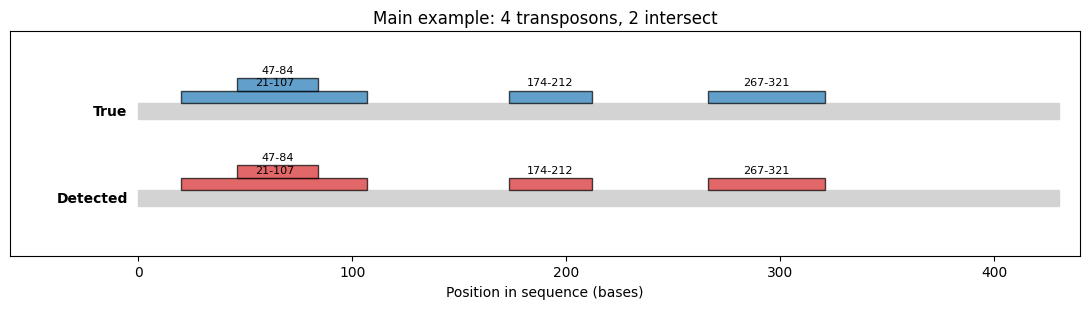

=== Case A: 3 transposons, no intersection (length 425) ===
TRUE     (start, end, 1-based): [(141, 193), (213, 258), (333, 383)]
DETECTED (start, end, 1-based): [(141, 193), (213, 258), (333, 383)]
All found correctly: True 



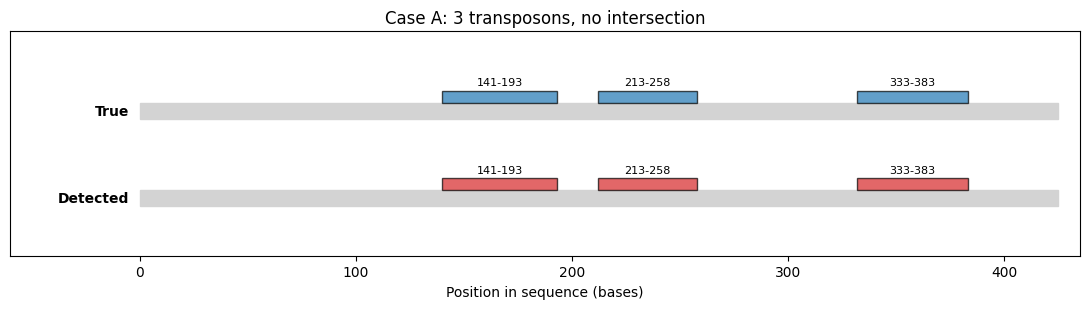

=== Case B: 3 transposons, 2 intersect (length 416) ===
TRUE     (start, end, 1-based): [(166, 258), (186, 237), (346, 393)]
DETECTED (start, end, 1-based): [(166, 258), (186, 237), (346, 393)]
All found correctly: True 



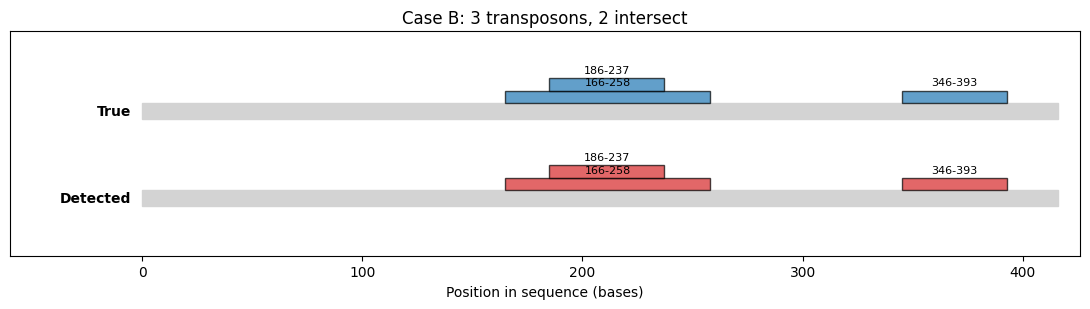

Stress test (200 random sequences each):
  3 transposons, nested=False: 99.5% fully correct
  3 transposons, nested=True : 99.5% fully correct
  4 transposons, nested=False: 99.0% fully correct
  4 transposons, nested=True : 99.0% fully correct


In [1]:
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ---------------- Parameters ----------------
IR_LEN  = 8   # length of the inverted repeat at each end of a transposon
TSD_LEN = 5   # length of the target site duplication (direct repeat)
COMP = {"A": "T", "T": "A", "G": "C", "C": "G"}


# ---------------- Helper functions ----------------
def random_dna(n):
    """Random DNA string of length n."""
    return "".join(random.choice("ACGT") for _ in range(n))


def revcomp(seq):
    """Reverse complement of a DNA string."""
    return "".join(COMP[b] for b in reversed(seq))


def make_transposon():
    """Transposon = IR + random middle + reverse complement of IR."""
    ir = random_dna(IR_LEN)
    middle = random_dna(random.randint(20, 40))
    return ir + middle + revcomp(ir)


# ---------------- Simulation ----------------
def too_close(pos, elements):
    """Avoid cutting right at the edge of an already inserted transposon."""
    return any(abs(pos - s) <= 2 * TSD_LEN or abs(pos - e) <= 2 * TSD_LEN
               for s, e in elements)


def insert_transposon(dna, elements, tn, pos):
    """host[:pos] + TARGET + transposon + TARGET + host[pos+TSD_LEN:]"""
    target = dna[pos:pos + TSD_LEN]
    new_dna = dna[:pos] + target + tn + target + dna[pos + TSD_LEN:]

    shift = TSD_LEN + len(tn)
    new_start = pos + TSD_LEN
    updated = []
    for s, e in elements:
        if s >= pos + TSD_LEN:                  # element is after the insertion
            updated.append((s + shift, e + shift))
        elif s < pos and e >= pos + TSD_LEN:    # new one landed INSIDE it
            updated.append((s, e + shift))
        else:                                   # element is before the insertion
            updated.append((s, e))
    updated.append((new_start, new_start + len(tn)))
    return new_dna, updated


def build_sequence(n_transposons=4, nested=True, seed=None):
    """Return (dna, true_positions). nested=True puts the 2nd transposon inside the 1st."""
    if seed is not None:
        random.seed(seed)
    dna = random_dna(random.randint(200, 330))
    elements = []   # (start, end): 0-based, end exclusive

    for i in range(n_transposons):
        tn = make_transposon()
        if nested and i == 1 and elements:
            s, e = elements[0]
            pos = random.randint(s + 3 * TSD_LEN, e - 3 * TSD_LEN)
        else:
            while True:
                pos = random.randint(TSD_LEN, len(dna) - 2 * TSD_LEN)
                if not too_close(pos, elements):
                    break
        dna, elements = insert_transposon(dna, elements, tn, pos)

    return dna, sorted(elements)


# ---------------- Detector ----------------
def detect_transposons(dna, min_len=2 * IR_LEN + 10, max_len=300):
    """Find (start, end) pairs with inverted repeats AND flanking direct repeats."""
    found = []
    for i in range(TSD_LEN, len(dna) - min_len - TSD_LEN):
        left_ir = dna[i:i + IR_LEN]
        for j in range(i + min_len, min(i + max_len, len(dna) - TSD_LEN) + 1):
            right_ir = dna[j - IR_LEN:j]
            if left_ir == revcomp(right_ir):                    # inverted repeats
                if dna[i - TSD_LEN:i] == dna[j:j + TSD_LEN]:    # direct repeats
                    found.append((i, j))
    return found


# ---------------- Plot ----------------
def plot_positions(dna, truth, detected, title=""):
    def levels(elements):
        return [sum(1 for s2, e2 in elements if s2 <= s and e <= e2 and (s2, e2) != (s, e))
                for s, e in elements]

    fig, ax = plt.subplots(figsize=(11, 3.2))
    for row, (name, elems, color) in enumerate([("True", truth, "tab:blue"),
                                                ("Detected", detected, "tab:red")]):
        y0 = 2.2 - row * 1.4
        ax.add_patch(Rectangle((0, y0), len(dna), 0.25, color="lightgray"))
        for (s, e), lv in zip(elems, levels(elems)):
            ax.add_patch(Rectangle((s, y0 + 0.25 + 0.2 * lv), e - s, 0.2,
                                   color=color, alpha=0.7, ec="black"))
            ax.text((s + e) / 2, y0 + 0.5 + 0.2 * lv, f"{s + 1}-{e}",
                    ha="center", va="bottom", fontsize=8)
        ax.text(-5, y0 + 0.12, name, ha="right", va="center", fontweight="bold")

    ax.set_xlim(-60, len(dna) + 10)
    ax.set_ylim(0, 3.6)
    ax.set_yticks([])
    ax.set_xlabel("Position in sequence (bases)")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def run_case(name, n_transposons, nested, seed, show_sequence=False):
    dna, truth = build_sequence(n_transposons, nested, seed)
    detected = detect_transposons(dna)
    print(f"=== {name} (length {len(dna)}) ===")
    if show_sequence:
        for k in range(0, len(dna), 60):
            print(f"{k + 1:4d}  {dna[k:k + 60]}")
    print("TRUE     (start, end, 1-based):", [(s + 1, e) for s, e in truth])
    print("DETECTED (start, end, 1-based):", [(s + 1, e) for s, e in detected])
    print("All found correctly:", sorted(detected) == truth, "\n")
    plot_positions(dna, truth, detected, name)


# ---------------- Run: main example + intersection tests ----------------
run_case("Main example: 4 transposons, 2 intersect", 4, True, seed=1, show_sequence=True)
run_case("Case A: 3 transposons, no intersection", 3, False, seed=3)
run_case("Case B: 3 transposons, 2 intersect", 3, True, seed=5)


# ---------------- Stress test ----------------
def accuracy(n_transposons, nested, runs=200):
    ok = 0
    for seed in range(runs):
        d, t = build_sequence(n_transposons, nested, seed=seed)
        if sorted(detect_transposons(d)) == t:
            ok += 1
    return ok / runs

print("Stress test (200 random sequences each):")
for n in (3, 4):
    for nested in (False, True):
        print(f"  {n} transposons, nested={nested!s:5}: "
              f"{accuracy(n, nested) * 100:.1f}% fully correct")

# Detecting possible transposon-like regions in a real viral genome

This section explains how to use the same idea from the lab on a real genome downloaded from NCBI.

## Goal

We want to download a viral genome sequence and search it for regions that look like transposons.

The logic is the same as in the notebook:

- a transposon-like segment often has terminal inverted repeats
- the insertion site often leaves a short direct repeat (target-site duplication)
- we apply a minimum repeat length of 10 bases to reduce false positives

## Workflow

1. Download a viral genome FASTA file from NCBI.
2. Save it locally, for example as `viral_genome.fasta`.
3. Read the sequence and remove the FASTA headers and line breaks.
4. Search for candidate regions where the ends are reverse complements of each other.
5. Check if there is a duplicated target sequence next to the candidate.
6. Keep only candidates with a minimum repeated motif length of 10 bases.

## Key idea

The detector is not looking for just any repeated DNA. It looks for a biological signature:

- left end = reverse complement of right end
- small duplicated sequence around the insertion site

This is the same logic used in the artificial lab example.

## Minimum length rule

We use:

```python
MIN_LEN = 10
```

This means that a candidate repeat shorter than 10 bases is ignored.

```python
COMP = {"A": "T", "T": "A", "G": "C", "C": "G"}

def revcomp(seq):
    return "".join(COMP[b] for b in reversed(seq))

MIN_LEN = 10
TSD_LEN = 5

candidates = []
for i in range(TSD_LEN, len(seq) - MIN_LEN - TSD_LEN):
    left_ir = seq[i:i + MIN_LEN]
    for j in range(i + MIN_LEN, min(i + 300, len(seq) - TSD_LEN) + 1):
        right_ir = seq[j - MIN_LEN:j]
        if left_ir == revcomp(right_ir):
            if seq[i - TSD_LEN:i] == seq[j:j + TSD_LEN]:
                candidates.append((i, j))
```

## Important note

This is a candidate search, not a final proof that a region is a real transposon.

A real viral genome contains many repeated motives, so the output should be treated as a list of possible transposon-like regions that need further biological checking.

## Summary

For a real NCBI viral genome, the procedure is:

- download the FASTA
- clean the sequence
- scan for reverse-complement terminal repeats
- require the repeat to be at least 10 bases long
- report possible transposon-like loci

This is the practical extension of the lab from synthetic DNA to real biological DNA.


In [ ]:
from pathlib import Path
from bisect import bisect_left, bisect_right

# Use the FASTA file copied into the current project folder.
fasta_path = Path("GCF_042242905.1_um_ofav_v1_genomic.fna")

if not fasta_path.exists():
    raise FileNotFoundError("The FASTA file was not found in the current project folder.")


def read_fasta(path):
    """Read a FASTA file and return only the sequence without headers."""
    lines = [line.strip() for line in path.read_text(errors="ignore").splitlines() if line.strip()]
    seq = "".join(line for line in lines if not line.startswith(">")).upper()
    return seq


def revcomp(seq, comp):
    return "".join(comp[base] for base in reversed(seq))


def detect_transposons_fast(dna, min_ir_len=10, tsd_len=5, min_span=30, max_span=200, max_hits=2000):
    """Fast transposon-like detector using an index of left IR positions."""
    comp = {"A": "T", "T": "A", "G": "C", "C": "G"}
    n = len(dna)
    hits = []

    # Index all possible left terminal IR positions by their k-mer.
    left_positions = {}
    left_stop = n - min_ir_len - tsd_len
    for i in range(tsd_len, left_stop + 1):
        kmer = dna[i:i + min_ir_len]
        if "N" in kmer:
            continue
        left_positions.setdefault(kmer, []).append(i)

    # Scan right boundaries and query matching left IRs in a bounded span range.
    right_start = min_span
    right_stop = n - tsd_len
    for j in range(right_start, right_stop + 1):
        right_ir = dna[j - min_ir_len:j]
        if "N" in right_ir:
            continue

        needed_left = revcomp(right_ir, comp)
        pos_list = left_positions.get(needed_left)
        if not pos_list:
            continue

        lo = bisect_left(pos_list, j - max_span)
        hi = bisect_right(pos_list, j - min_span)
        if lo == hi:
            continue

        right_tsd = dna[j:j + tsd_len]
        for i in pos_list[lo:hi]:
            if dna[i - tsd_len:i] == right_tsd:
                hits.append((i + 1, j))
                if len(hits) >= max_hits:
                    return hits

    return hits


seq = read_fasta(fasta_path)
print(f"File used: {fasta_path}")
print(f"Sequence length in FASTA: {len(seq)} bases")

# Limit the scan size so results appear quickly in class/lab runs.
MAX_BASES_TO_SCAN = 200_000
scan_seq = seq[:MAX_BASES_TO_SCAN]
if len(seq) > MAX_BASES_TO_SCAN:
    print(f"Scanning only first {MAX_BASES_TO_SCAN} bases for speed.")

hits = detect_transposons_fast(scan_seq, min_ir_len=10, tsd_len=5, min_span=30, max_span=200)
print(f"Candidate transposon-like regions: {len(hits)}")

if hits:
    for start, end in hits[:20]:
        print(f"start={start}, end={end}, length={end - start + 1}")
else:
    print("No candidate transposon-like regions were found in the scanned region.")

File used: GCF_042242905.1_um_ofav_v1_genomic.fna
Sequence length: 493936718 bases
